<a href="https://colab.research.google.com/github/shriyam943/Customer_Segmentaion/blob/main/CustomerSegmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
pwd

'/content'

In [ ]:
data = pd.read_csv('customer_segmentation.csv')

# Domain Analysis

In [ ]:
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536366,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:28,2.75,17850.0,United Kingdom
3,536367,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:34,3.39,13047.0,United Kingdom
4,536368,84029E,RED WOOLLY HOTTIE WHITE HEART,6,01-12-2010 08:34,3.39,13047.0,United Kingdom


In [ ]:
data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536366,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:28,2.75,17850.0,United Kingdom
3,536367,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:34,3.39,13047.0,United Kingdom
4,536368,84029E,RED WOOLLY HOTTIE WHITE HEART,6,01-12-2010 08:34,3.39,13047.0,United Kingdom
5,536369,22752,SET 7 BABUSHKA NESTING BOXES,2,01-12-2010 08:35,7.65,12583.0,France
6,536370,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,01-12-2010 08:45,4.25,NaN,Germany
7,536371,22633,HAND WARMER UNION JACK,6,01-12-2010 09:00,1.85,13748.0,United Kingdom
8,536372,22632,HAND WARMER RED POLKA DOT,6,01-12-2010 09:00,1.85,13748.0,United Kingdom
9,536373,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 09:02,1.69,15100.0,United Kingdom


In [ ]:
data.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID
count,32.000000,32.000000,32.000000,31.000000
mean,536379.531250,38.437500,3.703438,15068.612903
std,9.329054,175.588584,3.929030,1689.249906
min,536365.000000,-1.000000,0.550000,12472.000000
25%,536371.750000,5.250000,1.850000,13902.000000
50%,536379.500000,6.000000,2.100000,15291.000000
75%,536387.250000,10.000000,3.390000,15728.000000
max,536395.000000,1000.000000,18.000000,17850.000000


In [ ]:
data.loc[data['Quantity'] == -1]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
23,536387,22423,REGENCY CAKESTAND 3 TIER,-1,01-12-2010 10:15,12.75,17841.0,United Kingdom


In [ ]:
data.loc[data['Quantity']  < 0,'Quantity']= data['Quantity'].abs()

In [ ]:
data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536366,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:28,2.75,17850.0,United Kingdom
3,536367,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:34,3.39,13047.0,United Kingdom
4,536368,84029E,RED WOOLLY HOTTIE WHITE HEART,6,01-12-2010 08:34,3.39,13047.0,United Kingdom
5,536369,22752,SET 7 BABUSHKA NESTING BOXES,2,01-12-2010 08:35,7.65,12583.0,France
6,536370,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,01-12-2010 08:45,4.25,NaN,Germany
7,536371,22633,HAND WARMER UNION JACK,6,01-12-2010 09:00,1.85,13748.0,United Kingdom
8,536372,22632,HAND WARMER RED POLKA DOT,6,01-12-2010 09:00,1.85,13748.0,United Kingdom
9,536373,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 09:02,1.69,15100.0,United Kingdom


In [ ]:
data.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID
count,32.000000,32.000000,32.000000,31.000000
mean,536379.531250,38.500000,3.703438,15068.612903
std,9.329054,175.574449,3.929030,1689.249906
min,536365.000000,0.000000,0.550000,12472.000000
25%,536371.750000,5.250000,1.850000,13902.000000
50%,536379.500000,6.000000,2.100000,15291.000000
75%,536387.250000,10.000000,3.390000,15728.000000
max,536395.000000,1000.000000,18.000000,17850.000000


In [ ]:
data.dtypes

,0
InvoiceNo,int64
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [ ]:
data.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,1
Country,0


In [ ]:
data.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
27,536391,22469,HEART OF WICKER SMALL,6,01-12-2010 11:02,2.10,12472.0,Germany
28,536392,22470,HEART OF WICKER LARGE,6,01-12-2010 11:02,2.95,12472.0,Germany
29,536393,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1000,01-12-2010 11:15,2.55,12472.0,Germany
30,536394,22633,HAND WARMER UNION JACK,0,01-12-2010 11:30,1.85,14056.0,United Kingdom
31,536395,22632,HAND WARMER RED POLKA DOT,2,01-12-2010 11:30,1.85,14056.0,United Kingdom


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    32 non-null     int64  
 1   StockCode    32 non-null     object 
 2   Description  32 non-null     object 
 3   Quantity     32 non-null     int64  
 4   InvoiceDate  32 non-null     object 
 5   UnitPrice    32 non-null     float64
 6   CustomerID   31 non-null     float64
 7   Country      32 non-null     object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.1+ KB


In [ ]:
len(data.columns)

8

In [ ]:
data.value_counts()

InvoiceNo  StockCode  Description                          Quantity  InvoiceDate       UnitPrice  CustomerID  Country       
536365     71053      WHITE METAL LANTERN                  6         01-12-2010 08:26  3.39       17850.0     United Kingdom    1
           85123A     WHITE HANGING HEART T-LIGHT HOLDER   6         01-12-2010 08:26  2.55       17850.0     United Kingdom    1
536366     84406B     CREAM CUPID HEARTS COAT HANGER       8         01-12-2010 08:28  2.75       17850.0     United Kingdom    1
536367     84029G     KNITTED UNION FLAG HOT WATER BOTTLE  6         01-12-2010 08:34  3.39       13047.0     United Kingdom    1
536368     84029E     RED WOOLLY HOTTIE WHITE HEART        6         01-12-2010 08:34  3.39       13047.0     United Kingdom    1
536369     22752      SET 7 BABUSHKA NESTING BOXES         2         01-12-2010 08:35  7.65       12583.0     France            1
536371     22633      HAND WARMER UNION JACK               6         01-12-2010 09:00  1.85       13748.0     United Kingdom    1
536372     22632      HAND WARMER RED POLKA DOT            6         01-12-2010 09:00  1.85       13748.0     United Kingdom    1
536373     84879      ASSORTED COLOUR BIRD ORNAMENT        32        01-12-2010 09:02  1.69       15100.0     United Kingdom    1
536374     22745      POPPY'S PLAYHOUSE BEDROOM            6         01-12-2010 09:09  2.10       15291.0     Netherlands       1
536375     22748      POPPY'S PLAYHOUSE KITCHEN            6         01-12-2010 09:09  2.10       15291.0     Netherlands       1
536376     22749      POPPY'S PLAYHOUSE LIVINGROOM         6         01-12-2010 09:09  2.10       15291.0     Netherlands       1
536377     POST       POSTAGE                              1         01-12-2010 09:10  18.00      15291.0     Netherlands       1
536378     85099B     JUMBO BAG RED RETROSPOT              25        01-12-2010 09:25  1.95       14688.0     United Kingdom    1
536379     85099C     JUMBO BAG BAROQUE BLACK WHITE        10        01-12-2010 09:25  1.95       14688.0     United Kingdom    1
536380     85099F     JUMBO BAG STRAWBERRY                 10        01-12-2010 09:25  1.95       14688.0     United Kingdom    1
536381     21212      PACK OF 72 RETROSPOT CAKE CASES      12        01-12-2010 09:45  0.55       15311.0     United Kingdom    1
536382     21975      PACK OF 60 DINOSAUR CAKE CASES       12        01-12-2010 09:45  0.55       15311.0     United Kingdom    1
536383     21977      PACK OF 60 PINK PAISLEY CAKE CASES   12        01-12-2010 09:45  0.55       15311.0     United Kingdom    1
536384     84380      SET OF 3 BUTTERFLY COOKIE CUTTERS    6         01-12-2010 09:58  1.25       16098.0     Spain             1
536385     84406A     CREAM CUPID HEARTS COAT HANGER       8         01-12-2010 10:01  2.75       16098.0     Spain             1
536386     22423      REGENCY CAKESTAND 3 TIER             1         01-12-2010 10:10  12.75      17841.0     United Kingdom    1
536387     22423      REGENCY CAKESTAND 3 TIER             1         01-12-2010 10:15  12.75      17841.0     United Kingdom    1
536388     21755      LOVE BUILDING BLOCK WORD             3         01-12-2010 10:25  5.95       15358.0     United Kingdom    1
536389     21754      HOME BUILDING BLOCK WORD             3         01-12-2010 10:25  5.95       15358.0     United Kingdom    1
536390     21871      SAVE THE PLANET MUG                  12        01-12-2010 10:45  1.25       17021.0     Italy             1
536391     22469      HEART OF WICKER SMALL                6         01-12-2010 11:02  2.10       12472.0     Germany           1
536392     22470      HEART OF WICKER LARGE                6         01-12-2010 11:02  2.95       12472.0     Germany           1
536393     85123A     WHITE HANGING HEART T-LIGHT HOLDER   1000      01-12-2010 11:15  2.55       12472.0     Germany           1
536394     22633      HAND WARMER UNION JACK               0         01-12-2010 11:30  1.85       14056.0

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.drop('CustomerID', axis=1, inplace=True)


# EDA

<Axes: xlabel='Country', ylabel='count'>

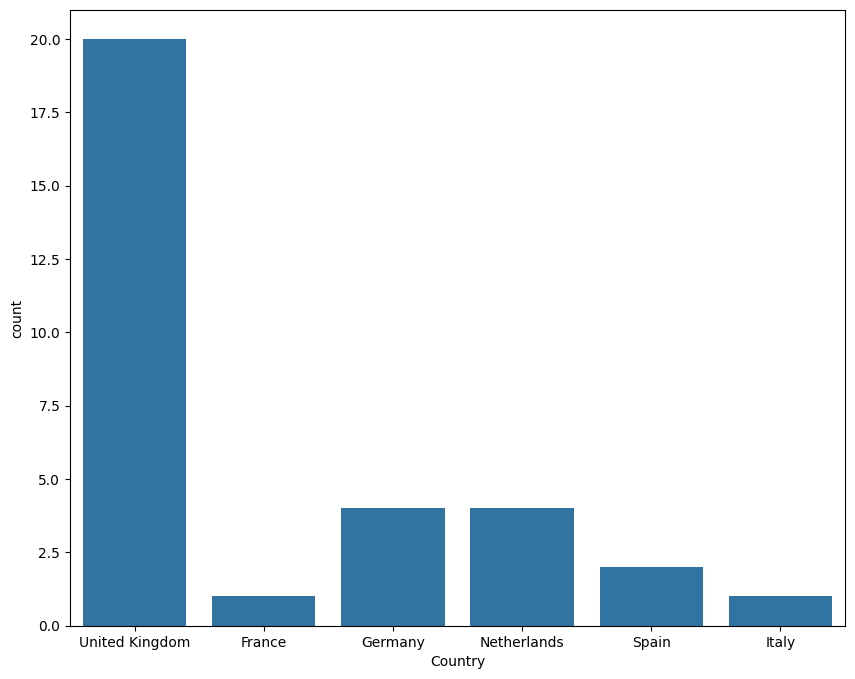

In [ ]:
plt.figure(figsize=(10,8))
sns.countplot(x='Country',data=data)


In [ ]:
data.nunique()

,0
InvoiceNo,31
StockCode,28
Description,27
Quantity,11
InvoiceDate,20
UnitPrice,15
Country,6


<Axes: xlabel='StockCode', ylabel='Count'>

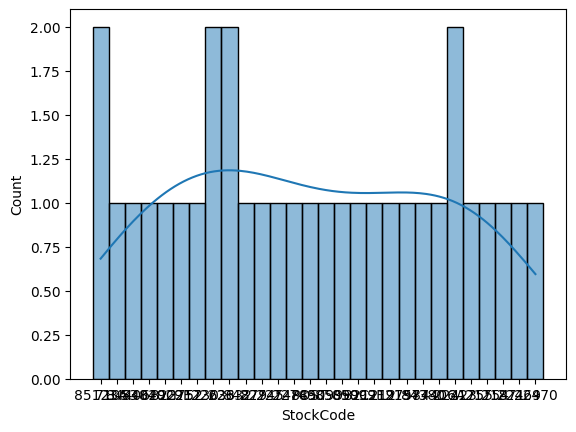

In [ ]:
sns.histplot(data['StockCode'],kde=True)

<Axes: ylabel='UnitPrice'>

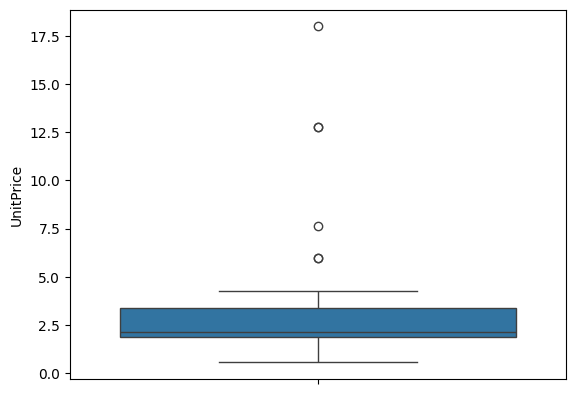

In [ ]:
sns.boxplot(data['UnitPrice'])

In [ ]:
q1=data['UnitPrice'].quantile(0.25)
q1

np.float64(1.85)

In [ ]:
q3=data['UnitPrice'].quantile(0.75)
q3

np.float64(3.39)

In [ ]:
iqr=q3-q1
iqr

np.float64(1.54)

In [ ]:
lower=q1-1.5*iqr
lower

np.float64(-0.45999999999999996)

In [ ]:
upper=q3+1.5*iqr
upper

np.float64(5.7)

In [ ]:
data.loc[data['UnitPrice']<lower]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country


In [ ]:
data.loc[data['UnitPrice']<upper]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,United Kingdom
2,536366,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:28,2.75,United Kingdom
3,536367,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:34,3.39,United Kingdom
4,536368,84029E,RED WOOLLY HOTTIE WHITE HEART,6,01-12-2010 08:34,3.39,United Kingdom
6,536370,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,01-12-2010 08:45,4.25,Germany
7,536371,22633,HAND WARMER UNION JACK,6,01-12-2010 09:00,1.85,United Kingdom
8,536372,22632,HAND WARMER RED POLKA DOT,6,01-12-2010 09:00,1.85,United Kingdom
9,536373,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 09:02,1.69,United Kingdom
10,536374,22745,POPPY'S PLAYHOUSE BEDROOM,6,01-12-2010 09:09,2.10,Netherlands


In [ ]:
len(data.loc[data['UnitPrice']>upper])

6

In [ ]:
len(data)

32

In [ ]:
(len(data.loc[data['UnitPrice']>upper])/len(data))*100

18.75

outlier cannot be handled because 18>5.

<Axes: ylabel='UnitPrice'>

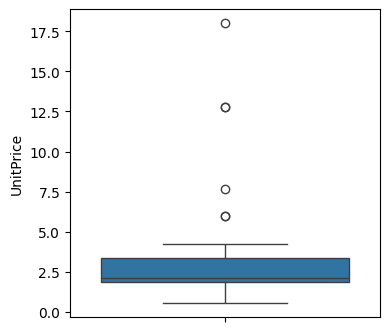

In [ ]:
plt.figure(figsize=(4,4))
sns.boxplot(data['UnitPrice'])

<Axes: ylabel='Quantity'>

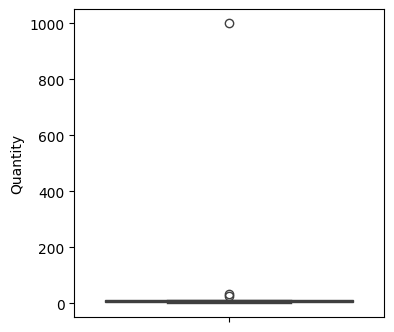

In [ ]:
plt.figure(figsize=(4,4))
sns.boxplot(data['Quantity'])

In [ ]:
q1=data['Quantity'].quantile(0.25)
q1

np.float64(5.25)

In [ ]:
q3=data['Quantity'].quantile(0.75)
q3

np.float64(10.0)

In [ ]:
iqr=q3-q1
iqr

np.float64(4.75)

In [ ]:
lower = q1-1.5*iqr
lower

np.float64(-1.875)

In [ ]:
upper=q3+1.5*iqr
upper

np.float64(17.125)

In [ ]:
data.loc[data['Quantity']<lower]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country


In [ ]:
data.loc[data['Quantity']>upper]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
9,536373,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 09:02,1.69,United Kingdom
14,536378,85099B,JUMBO BAG RED RETROSPOT,25,01-12-2010 09:25,1.95,United Kingdom
29,536393,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1000,01-12-2010 11:15,2.55,Germany


In [ ]:
len(data.loc[data['Quantity']>upper])

3

In [ ]:
len(data)

32

In [ ]:
(len(data.loc[data['Quantity']>upper])/len(data))*100

9.375

In [ ]:
data["TotalQuantity"] = data["Quantity"] * data["UnitPrice"]

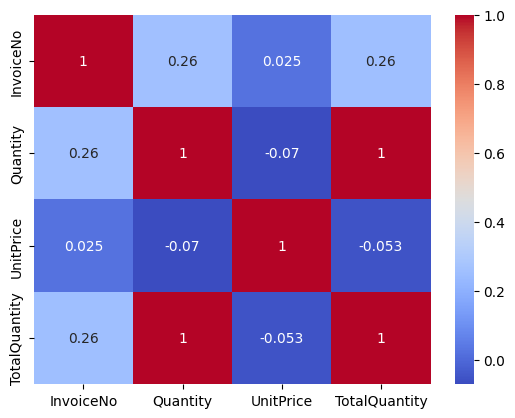

In [ ]:

numeric_data = data.select_dtypes(include='number')
corr = numeric_data.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()


# Model Building

In [ ]:
X=data[["Quantity","UnitPrice","TotalQuantity"]]
y=data[["Country"]]

In [ ]:
X=data[["Quantity","UnitPrice","TotalQuantity"]]

In [ ]:
y=data[["Country"]]

In [ ]:
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country,TotalQuantity
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,United Kingdom,20.34
2,536366,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:28,2.75,United Kingdom,22.00
3,536367,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:34,3.39,United Kingdom,20.34
4,536368,84029E,RED WOOLLY HOTTIE WHITE HEART,6,01-12-2010 08:34,3.39,United Kingdom,20.34


# K-Means

In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()


In [ ]:
X=pd.DataFrame(sc.fit_transform(X),columns=X.columns)
X

,Quantity,UnitPrice,TotalQuantity
0,-0.188069,-0.298265,-0.182783
1,-0.188069,-0.081051,-0.171352
2,-0.176495,-0.246548,-0.167587
3,-0.188069,-0.081051,-0.171352
4,-0.188069,-0.081051,-0.171352
5,-0.211215,1.020535,-0.182783
6,-0.188069,0.141335,-0.159649
7,-0.188069,-0.479277,-0.192309
8,-0.188069,-0.479277,-0.192309
9,-0.037614,-0.520651,-0.094827


In [ ]:
from sklearn.cluster import KMeans

In [ ]:
X

,Quantity,UnitPrice,TotalQuantity
0,-0.188069,-0.298265,-0.182783
1,-0.188069,-0.081051,-0.171352
2,-0.176495,-0.246548,-0.167587
3,-0.188069,-0.081051,-0.171352
4,-0.188069,-0.081051,-0.171352
5,-0.211215,1.020535,-0.182783
6,-0.188069,0.141335,-0.159649
7,-0.188069,-0.479277,-0.192309
8,-0.188069,-0.479277,-0.192309
9,-0.037614,-0.520651,-0.094827


In [ ]:
WCSS = []

for k in range(2,8):
            model = KMeans(n_clusters=k,random_state=10)
            model.fit(X)
            WCSS.append(model.inertia_)
print(WCSS)

[31.970809913176065, 6.830204243111058, 2.7243335820658214, 1.495541501182191, 0.6664330553538701, 0.3805573202234075]


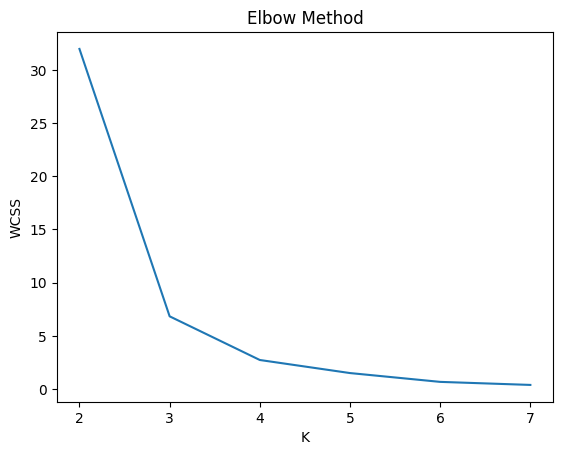

In [ ]:
plt.plot(range(2,8),WCSS)
plt.xlabel('K')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
model1 = KMeans(n_clusters=3,random_state=10)
model1.fit(X)

KMeans(n_clusters=3, random_state=10)

In [ ]:
model1.labels_

array([2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2,
       0, 0, 2, 2, 2, 2, 2, 1, 2, 2], dtype=int32)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(y)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
print(silhouette_scores)

[np.float64(0.8605085528619028), np.float64(0.7990453956465298), np.float64(0.7161470003952539), np.float64(0.6733734381160055), np.float64(0.5604167661394185), np.float64(0.5828002462369376), np.float64(0.5782026970939023), np.float64(0.5930442171593393), np.float64(0.6066102133408322)]


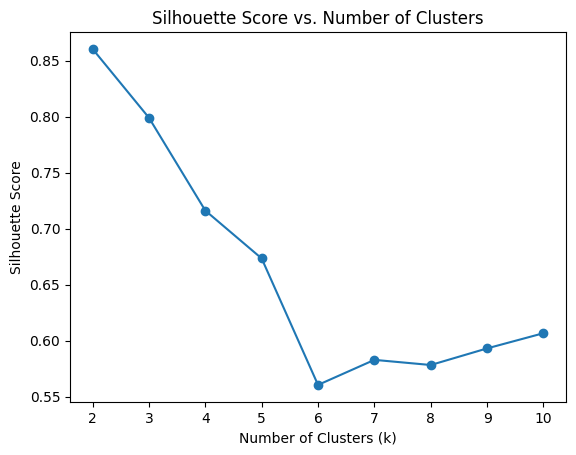

In [ ]:
plt.figure()
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.cluster import KMeans

wcss = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)


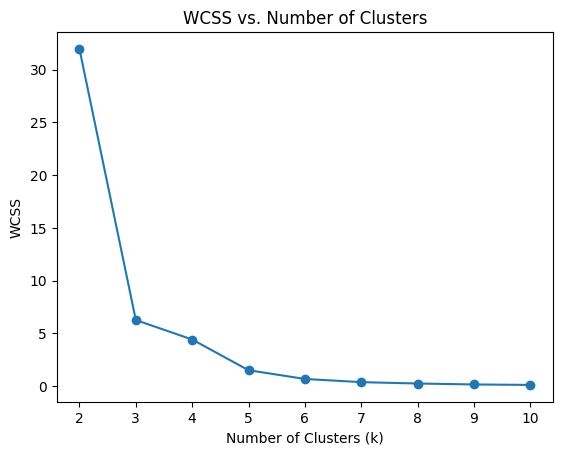

In [ ]:
plt.figure()
plt.plot(k_values, wcss, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('WCSS vs. Number of Clusters')
plt.show()